# 04 · Block 3 — camera model

Goal: convert pixels to metres on the ground, so outputs mean the same thing at every row, and so we know how wide the track *should* look on any row.

## Pinhole on flat ground

A level camera at height $h$ with focal length $f$ (px). A ground point at forward distance $z$ and lateral offset $x$ appears at

$$v - v_h = \frac{f\,h}{z}, \qquad u - c_x = \frac{f\,x}{z}$$

with $v_h$ the horizon row and $c_x = W/2$. Solving:

$$x = h\,\frac{u - c_x}{v - v_h}, \qquad z = \frac{f\,h}{v - v_h}$$

- Lateral position needs only $h$ and $v_h$. Distance also needs $f$.
- A ground width $w$ spans $w\,(v - v_h)/h$ pixels on row $v$ — linear in $v$, as seen in 01.
- A small camera pitch only moves $v_h$, which calibration absorbs.

In [1]:
%load_ext autoreload
%autoreload 2
import math
import numpy as np
import matplotlib.pyplot as plt
from helpers import SyntheticTrack, synthetic_drive, show, table, use_style
use_style()
from lanedet.mask import to_float, yellow_mask
from lanedet.scan import band_profile, find_lines

This cell saves the block to `lanedet/camera.py`. The next cell imports it.

In [2]:
%%writefile lanedet/camera.py
"""Block 3 - camera model: image pixels <-> metres on a flat ground plane (level pinhole camera)."""

from dataclasses import dataclass

import numpy as np


@dataclass
class Camera:
    width: int  # px
    height: int  # px
    focal: float  # px
    cam_height: float  # m above the ground
    v_horizon: float  # row of the horizon, px

    @property
    def cx(self) -> float:
        return self.width / 2

    def distance(self, v):
        """Forward distance z (m) of the ground seen at row v."""
        return self.focal * self.cam_height / (np.asarray(v, dtype=float) - self.v_horizon)

    def lateral(self, u, v):
        """Lateral position x (m, + right) of the ground point at pixel (u, v)."""
        return self.cam_height * (np.asarray(u, dtype=float) - self.cx) / (np.asarray(v, dtype=float) - self.v_horizon)

    def to_pixel_u(self, x, v):
        """Column u where a ground point at lateral x appears on row v."""
        return self.cx + np.asarray(x, dtype=float) * (np.asarray(v, dtype=float) - self.v_horizon) / self.cam_height

    def width_px(self, metres, v):
        """How many pixels a ground length of `metres` (across the image) spans on row v."""
        return np.asarray(metres, dtype=float) * (np.asarray(v, dtype=float) - self.v_horizon) / self.cam_height


def calibrate(rows, left_u, right_u, width: int, height: int, focal: float, cam_height: float) -> Camera:
    """Recover the horizon row from left/right line positions on a straight track.

    On flat ground both lines are straight in the image and meet at the horizon.
    """
    rows = np.asarray(rows, dtype=float)
    spread = np.asarray(right_u, dtype=float) - np.asarray(left_u, dtype=float)
    slope, intercept = np.polyfit(rows, spread, 1)  # spread = slope * (v - v_horizon)
    return Camera(width, height, focal, cam_height, v_horizon=-intercept / slope)

Writing lanedet/camera.py


In [3]:
from lanedet.camera import Camera, calibrate

track = SyntheticTrack(offset=0.07, yaw=0.05)
cam = Camera(track.width, track.height, track.focal, track.cam_height, track.v_horizon)
mask = yellow_mask(to_float(track.render()))

rows = []
for band in ((50, 54), (56, 60), (64, 68), (72, 76), (80, 84)):
    v = sum(band) / 2
    lines = find_lines(band_profile(mask, band))
    if len(lines) != 2:
        continue
    xl, xr = (float(cam.lateral(l.u, v)) for l in lines)
    z = float(cam.distance(v))
    rows.append({"row v": v, "z (m)": z, "spacing (px)": lines[1].u - lines[0].u,
                 "half-width (m)": (xr - xl) / 2, "centre (m)": (xl + xr) / 2, "true centre (m)": track.centre_x(z)})
table(rows)

row v,z (m),spacing (px),half-width (m),centre (m),true centre (m)
52.000,0.990,38.798,0.300,0.122,0.120
58.000,0.722,53.066,0.299,0.107,0.106
66.000,0.531,72.452,0.300,0.097,0.097
74.000,0.419,91.593,0.300,0.090,0.091


Spacing in pixels changes with the row; the half-width in metres stays at 0.30 m and the centre matches the truth.

## Calibration

For a real camera: $f = \tfrac{W/2}{\tan(\text{HFOV}/2)}$ from the spec sheet, $h$ with a tape measure. The horizon row depends on mounting pitch — measure it from one frame of a straight track: the spacing is linear in $v$ and hits zero at $v_h$. The slope gives $2w/h$, so it also measures the track width.

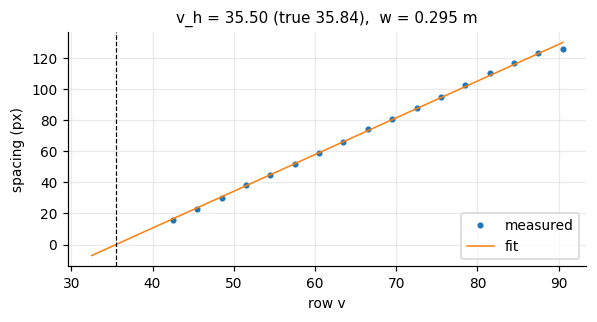

In [4]:
straight = yellow_mask(to_float(SyntheticTrack().render()))
vs, left, right = [], [], []
for r in range(42, 96, 3):
    lines = find_lines(band_profile(straight, (r, r + 1)))
    if len(lines) == 2:
        vs.append(r + 0.5)
        left.append(lines[0].u)
        right.append(lines[1].u)

cal = calibrate(vs, left, right, 128, 128, focal=64.0, cam_height=0.25)
spread = np.subtract(right, left)
slope, icpt = np.polyfit(vs, spread, 1)

fig, ax = plt.subplots(figsize=(5.5, 3))
vv = np.linspace(cal.v_horizon - 3, max(vs), 50)
ax.plot(vs, spread, "o", ms=3, label="measured")
ax.plot(vv, slope * vv + icpt, lw=1, label="fit")
ax.axvline(cal.v_horizon, color="k", ls="--", lw=0.8)
ax.set(xlabel="row v", ylabel="spacing (px)",
       title=f"v_h = {cal.v_horizon:.2f} (true {track.v_horizon:.2f}),  w = {slope * 0.25 / 2:.3f} m")
ax.legend()
plt.tight_layout()
plt.show()

## Choosing the two bands

- **near** — lateral offset close to the car, where pixels per metre are highest.
- **far** — lookahead; the change of centre between near and far gives the heading.

Choose by distance and convert with $v = v_h + f h / z$. Constraint: both lines should stay in view for typical offsets.

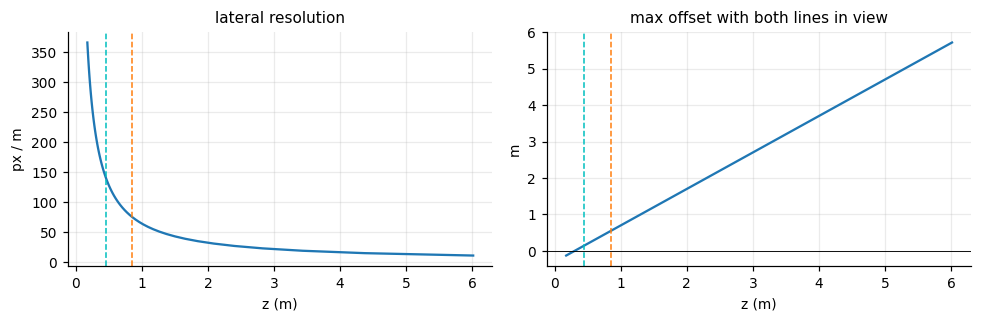

band,z (m),row v,rows
near,0.450,71.396,"(68, 75)"
far,0.850,54.664,"(52, 58)"


In [5]:
v = np.arange(int(cam.v_horizon) + 3, 128) + 0.5
z = cam.distance(v)
px_per_m = cam.width_px(1.0, v)
max_offset = (cam.width / 2 - cam.width_px(track.half_width, v)) / px_per_m

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(z, px_per_m)
ax[0].set(xlabel="z (m)", ylabel="px / m", title="lateral resolution")
ax[1].plot(z, max_offset)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set(xlabel="z (m)", ylabel="m", title="max offset with both lines in view")
for zz, c in ((0.45, "c"), (0.85, "tab:orange")):
    for a in ax:
        a.axvline(zz, color=c, ls="--", lw=1)
plt.tight_layout()
plt.show()

table([
    {"band": name, "z (m)": zz, "row v": float(cam.v_horizon + cam.focal * cam.cam_height / zz), "rows": str(rr)}
    for name, zz, rr in (("near", 0.45, (68, 75)), ("far", 0.85, (52, 58)))
])

Near at 0.45 m: ~140 px/m, both lines visible up to ±0.15 m. Far at 0.85 m: visible up to ±0.5 m at half the resolution. Bands of 6–7 rows centred on those rows — the values used in 03.

## Check

In [6]:
for tr in (SyntheticTrack(), SyntheticTrack(offset=-0.1, yaw=0.1)):
    m = yellow_mask(to_float(tr.render()))
    for band in ((68, 75), (52, 58)):
        v_b = sum(band) / 2
        lines = find_lines(band_profile(m, band))
        assert len(lines) == 2
        xl, xr = (float(cam.lateral(l.u, v_b)) for l in lines)
        assert abs((xl + xr) / 2 - tr.centre_x(float(cam.distance(v_b)))) < 0.005
        assert abs((xr - xl) / 2 - tr.half_width) < 0.01
assert abs(cal.v_horizon - track.v_horizon) < 0.5
assert np.isclose(cam.to_pixel_u(cam.lateral(30.0, 70.0), 70.0), 30.0)

## Exercises

1. The camera height is measured 10 % too high. What happens to `x`? To `z`? To `e_heading`?
2. Choose bands for a 60° FOV camera (`focal = 64 / tan(30°)`).